# Project 2 Data Sources
This projects builds upon project 1 in IND320. It investigates Norwegian reservoir levels and electricity transfers using data from Norwegian Water Resources and Energy Directorate (NVE) and the European Network of Transmission System Operators for Electricity (ENTSO-E). The project combines Python, Apache Spark, Apache Cassandra, MongoDB, and Streamlit.

The github repository is found here: xxx link

The streamlit application is here: xxx link

### Environment and libraries

In [ ]:
# Import the tools we need
import os
import pandas as pd
import requests
import matplotlib.pyplot as plt

# Choose the years we want to study
years = [2024, 2025]


Years: [2024, 2025]


### 2. NVE Magasinstatistikk API

Source: NVE documentation and API specification. EL covers electricity bidding/price areas, NO denotes the national aggregate, and VASS denotes hydrological regions. Area numbers are identifiers within an area type, not universally shared identifiers. The source reports weekly ISO calendar dates; the date and ISO year/week may differ near New Year.

In [34]:
# Get data from NVE
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url, timeout=60)
response.raise_for_status()

# Turn the data into a table
df = pd.DataFrame(response.json())

# Show the first 5 rows
display(df.head())
  

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [9]:
# Renaming colums as in project 1
df = df.rename(columns={
    "dato_Id": "date_id",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_level_previous_week",
    "endring_fyllingsgrad": "change_in_fill_level"
})


# Change the date column into real dates
df["date"] = pd.to_datetime(df["date_id"])

# Show the table
display(df.head())

,date_id,area_type,area_number,iso_year,iso_week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level,date
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833,1995-09-03
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046,2020-11-15
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694,2011-08-28
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157,1998-07-05
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301,2011-03-27


In [ ]:
# Select data for the whole of Norway
norway = df[
    (df["area_type"] == "NO") &
    (df["area_number"] == 0)
]

# Put the dates in order
norway = norway.sort_values("date")

# Show the first 5 rows
display(norway.head())

,date_id,area_type,area_number,iso_year,iso_week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level,date
9678,1995-01-08,NO,0,1995,1,0.607988,87.43758,53.161003,0001-01-01T00:00:00,0.752631,-0.144643,1995-01-08
9731,1995-01-15,NO,0,1995,2,0.582088,87.43758,50.896374,0001-01-01T00:00:00,0.607988,-0.025900,1995-01-15
9521,1995-01-22,NO,0,1995,3,0.562121,87.43758,49.150486,0001-01-01T00:00:00,0.582088,-0.019967,1995-01-22
9704,1995-01-29,NO,0,1995,4,0.534222,87.43758,46.711033,0001-01-01T00:00:00,0.562121,-0.027899,1995-01-29
9751,1995-02-05,NO,0,1995,5,0.506221,87.43758,44.262720,0001-01-01T00:00:00,0.534222,-0.028001,1995-02-05


In [12]:

columns = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_level_previous_week",
    "change_in_fill_level"
]


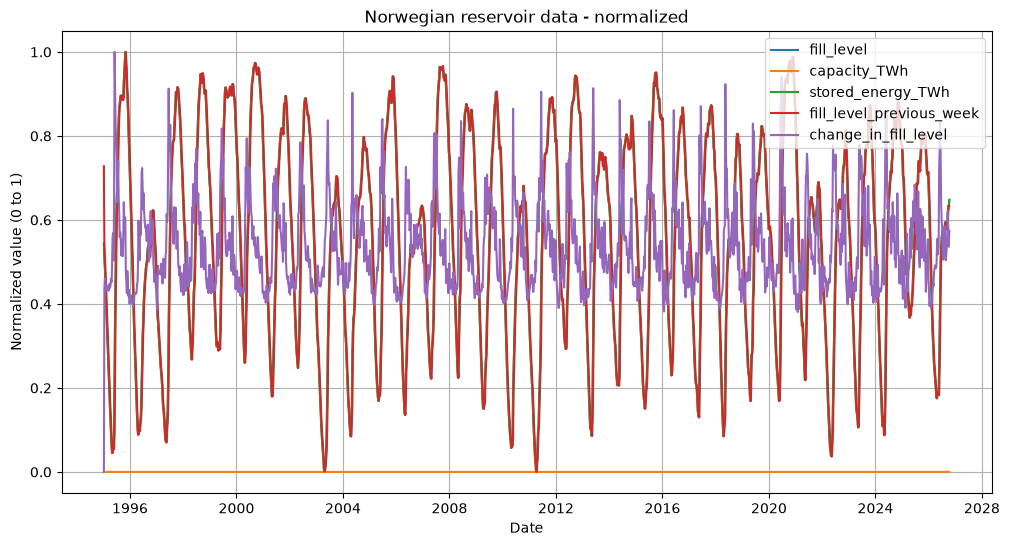

In [13]:
# Copy the measurements we want to compare
normalized = norway[columns].copy()

# Change each column to a scale from 0 to 1
for column in columns:
    low = normalized[column].min()
    high = normalized[column].max()

    if high > low:
        normalized[column] = (normalized[column] - low) / (high - low)
    else:
        normalized[column] = 0

# Make one graph
plt.figure(figsize=(12, 6))

# Add all the lines
for column in columns:
    plt.plot(norway["date"], normalized[column], label=column)

plt.title("Norwegian reservoir data - normalized")
plt.xlabel("Date")
plt.ylabel("Normalized value (0 to 1)")

plt.legend()
plt.grid()
plt.show()


### Connect to ENTSO-E

In [14]:
from entsoe import EntsoePandasClient

# Get my secret API token
token = os.getenv("ENTSOE_API_TOKEN")

# Check that the token exists
if not token:
    raise ValueError("ENTSOE_API_TOKEN is missing")

# Connect to ENTSO-E
client = EntsoePandasClient(api_key=token)


In [15]:
# Choose our dates
start = pd.Timestamp("2025-01-01", tz="UTC")
end = pd.Timestamp("2025-02-01", tz="UTC")

# Download electricity flow from Norway to Denmark
flow = client.query_crossborder_flows(
    "NO_2",
    "DK_1",
    start=start,
    end=end
)

# Show the first 5 observations
display(flow.head())
  

2025-01-01 01:00:00+01:00    0.0
2025-01-01 02:00:00+01:00    0.0
2025-01-01 03:00:00+01:00    0.0
2025-01-01 04:00:00+01:00    0.0
2025-01-01 05:00:00+01:00    0.0
Freq: 60min, dtype: float64

In [16]:
# Electricity going out of Norway
outflow = client.query_crossborder_flows(
    "NO_2", "DK_1",
    start=start, end=end
)

# Electricity coming into Norway
inflow = client.query_crossborder_flows(
    "DK_1", "NO_2",
    start=start, end=end
)

print("Out of Norway:")
display(outflow.head())

print("Into Norway:")
display(inflow.head())


Out of Norway:


2025-01-01 01:00:00+01:00    0.0
2025-01-01 02:00:00+01:00    0.0
2025-01-01 03:00:00+01:00    0.0
2025-01-01 04:00:00+01:00    0.0
2025-01-01 05:00:00+01:00    0.0
Freq: 60min, dtype: float64

Into Norway:


2025-01-01 01:00:00+01:00    1603.9600
2025-01-01 02:00:00+01:00    1585.1300
2025-01-01 03:00:00+01:00    1330.3925
2025-01-01 04:00:00+01:00    1237.3875
2025-01-01 05:00:00+01:00    1200.2150
Freq: 60min, dtype: float64

In [19]:
# Choose the connections
borders = [
    ("NO_2", "DK_1"),
    ("NO_1", "SE_3"),
    ("NO_2", "NL")
]

# Choose the months to download
months = pd.date_range(
    "2024-01-01",
    "2026-01-01",
    freq="MS",
    tz="UTC"
)

# Make empty lists to store our results
all_data = []
errors = []

# Go through each connection
for norway, foreign in borders:

    # Download both directions
    for direction, start_zone, end_zone in [
        ("Out of Norway", norway, foreign),
        ("Into Norway", foreign, norway)
    ]:

        # Download one month at a time
        for start, end in zip(months[:-1], months[1:]):

            try:
                flow = client.query_crossborder_flows(
                    start_zone, end_zone,
                    start=start, end=end
                )

                # Make a table
                part = flow.to_frame(name="mw")
                part = part.reset_index()
                part.columns = ["date", "mw"]

                # Add information about the connection
                part["connection"] = norway + "-" + foreign
                part["direction"] = direction

                # Save the table
                all_data.append(part)

            except Exception as error:
                print("Problem:", start_zone, end_zone, start)
                errors.append(str(error))

# Put all the tables together
if not all_data:
    raise ValueError("No electricity data was downloaded")

flows = pd.concat(all_data, ignore_index=True)

# Sort and remove duplicate observations
flows = flows.drop_duplicates(
    ["date", "connection", "direction"]
)

flows = flows.sort_values("date")

# Show the data
display(flows.head())
print("Download problems:", len(errors))
  

,date,mw,connection,direction
0,2024-01-01 01:00:00+01:00,0.00,NO_2-DK_1,Out of Norway
73680,2024-01-01 01:00:00+01:00,0.00,NO_1-SE_3,Out of Norway
97992,2024-01-01 01:00:00+01:00,1822.15,NO_1-SE_3,Into Norway
122304,2024-01-01 01:00:00+01:00,0.00,NO_2-NL,Out of Norway
185712,2024-01-01 01:00:00+01:00,648.37,NO_2-NL,Into Norway


Download problems: 0


### Cassandra and Spark

In [21]:
# Import the Cassandra tool
from cassandra.cluster import Cluster

# Connect to Cassandra on my computer
cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect()

print("Connected to Cassandra")
  

Connected to Cassandra


In [22]:

# Create a keyspace for our project
session.execute("""
CREATE KEYSPACE IF NOT EXISTS ind320
WITH replication = {
    'class': 'SimpleStrategy',
    'replication_factor': 1
}
""")

# Create a table for electricity data
session.execute("""
CREATE TABLE IF NOT EXISTS ind320.crossborder_flows (
    connection text,
    direction text,
    timestamp_utc timestamp,
    mw double,
    duration_hours double,
    mwh double,
    year int,
    month int,
    PRIMARY KEY ((connection, direction), timestamp_utc)
)
""")

print("Cassandra table is ready")
  

Cassandra table is ready


In [39]:
import subprocess

result = subprocess.run(
    ["java", "-version"],
    capture_output=True,
    text=True,
    timeout=10
)

print(result.stderr)

openjdk version "17.0.20.1" 2026-08-18
OpenJDK Runtime Environment Temurin-17.0.20.1+1 (build 17.0.20.1+1)
OpenJDK 64-Bit Server VM Temurin-17.0.20.1+1 (build 17.0.20.1+1, mixed mode, sharing)



In [40]:
from pyspark.sql import SparkSession

# Start Spark with Cassandra support
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("IND320")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .getOrCreate()
)

print("Spark version:", spark.version)



Py4JJavaError: An error occurred while calling None.org.apache.spark.api.java.JavaSparkContext.
: java.lang.RuntimeException: java.io.FileNotFoundException: java.io.FileNotFoundException: HADOOP_HOME and hadoop.home.dir are unset. -see https://wiki.apache.org/hadoop/WindowsProblems
	at org.apache.hadoop.util.Shell.getWinUtilsPath(Shell.java:735)
	at org.apache.hadoop.util.Shell.getSetPermissionCommand(Shell.java:270)
	at org.apache.hadoop.fs.FileUtil.chmod(FileUtil.java:1139)
	at org.apache.hadoop.fs.FileUtil.chmod(FileUtil.java:1125)
	at org.apache.spark.util.Utils$.fetchFile(Utils.scala:489)
	at org.apache.spark.SparkContext.addFile(SparkContext.scala:1795)
	at org.apache.spark.SparkContext.$anonfun$new$16(SparkContext.scala:533)
	at org.apache.spark.SparkContext.$anonfun$new$16$adapted(SparkContext.scala:533)
	at scala.collection.immutable.List.foreach(List.scala:431)
	at org.apache.spark.SparkContext.<init>(SparkContext.scala:533)
	at org.apache.spark.api.java.JavaSparkC

In [ ]:
# Check if Spark can find the Cassandra connector
try:
    spark._jvm.java.lang.Class.forName(
        "org.apache.spark.sql.cassandra.DefaultSource"
    )
    print("Cassandra connector found!")

except Exception as error:
    print("Cassandra connector not found!")
    print(str(error)[:500])

Py4JJavaError: An error occurred while calling o149.load.
: org.apache.spark.SparkClassNotFoundException: [DATA_SOURCE_NOT_FOUND] Failed to find the data source: org.apache.spark.sql.cassandra. Please find packages at `https://spark.apache.org/third-party-projects.html`.
	at org.apache.spark.sql.errors.QueryExecutionErrors$.dataSourceNotFoundError(QueryExecutionErrors.scala:724)
	at org.apache.spark.sql.execution.datasources.DataSource$.lookupDataSource(DataSource.scala:647)
	at org.apache.spark.sql.execution.datasources.DataSource$.lookupDataSourceV2(DataSource.scala:697)
	at org.apache.spark.sql.DataFrameReader.load(DataFrameReader.scala:208)
	at org.apache.spark.sql.DataFrameReader.load(DataFrameReader.scala:172)
	at java.base/jdk.internal.reflect.NativeMethodAccessorImpl.invoke0(Native Method)
	at java.base/jdk.internal.reflect.NativeMethodAccessorImpl.invoke(NativeMethodAccessorImpl.java:77)
	at java.base/jdk.internal.reflect.DelegatingMethodAccessorImpl.invoke(DelegatingM

In [ ]:
# Make a copy of the downloaded data
records = flows.copy()

# Make sure our energy calculations exist
if "mwh" not in records.columns:
    raise ValueError("Calculate MWh before saving the data")

if "duration_hours" not in records.columns:
    raise ValueError("We need the real measurement duration")

# Use the correct date column name
if "date" in records.columns:
    records = records.rename(
        columns={"date": "timestamp_utc"}
    )

# Make sure timestamps are UTC
records["timestamp_utc"] = pd.to_datetime(
    records["timestamp_utc"], utc=True
)

# Create year and month columns
records["year"] = records["timestamp_utc"].dt.year
records["month"] = records["timestamp_utc"].dt.month

# Select the columns we want to save
columns = [
    "connection", "direction", "timestamp_utc",
    "mw", "duration_hours", "mwh", "year", "month"
]

records = records[columns]

# Remove rows without essential values
records = records.dropna(subset=columns)
s
# Convert dates to UTC timestamps without timezone labels
records["timestamp_utc"] = (
    records["timestamp_utc"].dt.tz_localize(None)
)

# Convert our Pandas table into a Spark table
spark_df = spark.createDataFrame(records)

# Save the Spark table in Cassandra
(
    spark_df.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(table="crossborder_flows", keyspace="ind320")
    .save()
)

print("Data saved to Cassandra")
  

Py4JJavaError: An error occurred while calling o143.save.
: org.apache.spark.SparkClassNotFoundException: [DATA_SOURCE_NOT_FOUND] Failed to find the data source: org.apache.spark.sql.cassandra. Please find packages at `https://spark.apache.org/third-party-projects.html`.
	at org.apache.spark.sql.errors.QueryExecutionErrors$.dataSourceNotFoundError(QueryExecutionErrors.scala:724)
	at org.apache.spark.sql.execution.datasources.DataSource$.lookupDataSource(DataSource.scala:647)
	at org.apache.spark.sql.execution.datasources.DataSource$.lookupDataSourceV2(DataSource.scala:697)
	at org.apache.spark.sql.DataFrameWriter.lookupV2Provider(DataFrameWriter.scala:863)
	at org.apache.spark.sql.DataFrameWriter.saveInternal(DataFrameWriter.scala:257)
	at org.apache.spark.sql.DataFrameWriter.save(DataFrameWriter.scala:248)
	at java.base/jdk.internal.reflect.NativeMethodAccessorImpl.invoke0(Native Method)
	at java.base/jdk.internal.reflect.NativeMethodAccessorImpl.invoke(NativeMethodAccessorImp

### Electricity Graphs

In [26]:
# Make a copy of our electricity data
data = flows.copy()

# Get the year and month from each date
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month

# Show the first five rows
display(data.head())
  

,date,mw,connection,direction,duration_hours,mwh,year,month
0,2024-01-01 00:00:00+00:00,0.00,NO_2-DK_1,Out of Norway,1,0.00,2024,1
73680,2024-01-01 00:00:00+00:00,0.00,NO_1-SE_3,Out of Norway,1,0.00,2024,1
97992,2024-01-01 00:00:00+00:00,1822.15,NO_1-SE_3,Into Norway,1,1822.15,2024,1
122304,2024-01-01 00:00:00+00:00,0.00,NO_2-NL,Out of Norway,1,0.00,2024,1
185712,2024-01-01 00:00:00+00:00,648.37,NO_2-NL,Into Norway,1,648.37,2024,1


In [27]:

# Add up electricity for each year and direction
annual = (
    data.groupby(["connection", "year", "direction"])["mwh"]
    .sum()
    .reset_index()
)

# Show the totals
display(annual)

,connection,year,direction,mwh
0,NO_1-SE_3,2024,Into Norway,5.389455e+06
1,NO_1-SE_3,2024,Out of Norway,1.505030e+06
2,NO_1-SE_3,2025,Into Norway,1.207357e+07
3,NO_1-SE_3,2025,Out of Norway,2.805757e+06
4,NO_2-DK_1,2024,Into Norway,1.652846e+06
5,NO_2-DK_1,2024,Out of Norway,8.119131e+06
6,NO_2-DK_1,2025,Into Norway,4.144112e+06
7,NO_2-DK_1,2025,Out of Norway,2.482030e+07
8,NO_2-NL,2024,Into Norway,1.666378e+06
9,NO_2-NL,2024,Out of Norway,1.208686e+07


ValueError: All wedge sizes are zero

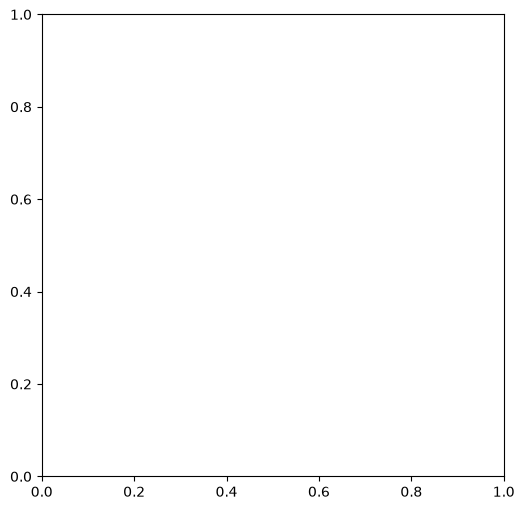

In [41]:
# Choose connection and year
connection = "NO2-DK1"
year = 2025

# Select the data we want
pie = annual[
    (annual["connection"] == connection) &
    (annual["year"] == year)
]

# Make the pie chart
plt.figure(figsize=(6, 6))

plt.pie(
    pie["mwh"],
    labels=pie["direction"],
    autopct="%1.1f%%"
)

plt.title("Electricity transfer: " + connection)
plt.show()


In [42]:
# Group electricity measurements by day
daily = (
    data.groupby(
        ["connection", "direction", "year", "month", "date"]
    )[["mwh", "duration_hours"]]
    .sum()
    .reset_index()
)

# Calculate average MW for each day
daily["mean_mw"] = (
    daily["mwh"] / daily["duration_hours"]
)

# Make sure dates work with Matplotlib
daily["date"] = pd.to_datetime(daily["date"])

# Show the first five rows
display(daily.head())  

,connection,direction,year,month,date,mwh,duration_hours,mean_mw
0,NO_1-SE_3,Into Norway,2024,1,2024-01-01 00:00:00+00:00,1822.15,1,1822.15
1,NO_1-SE_3,Into Norway,2024,1,2024-01-01 01:00:00+00:00,1775.05,1,1775.05
2,NO_1-SE_3,Into Norway,2024,1,2024-01-01 02:00:00+00:00,1601.27,1,1601.27
3,NO_1-SE_3,Into Norway,2024,1,2024-01-01 03:00:00+00:00,1533.96,1,1533.96
4,NO_1-SE_3,Into Norway,2024,1,2024-01-01 04:00:00+00:00,1322.37,1,1322.37


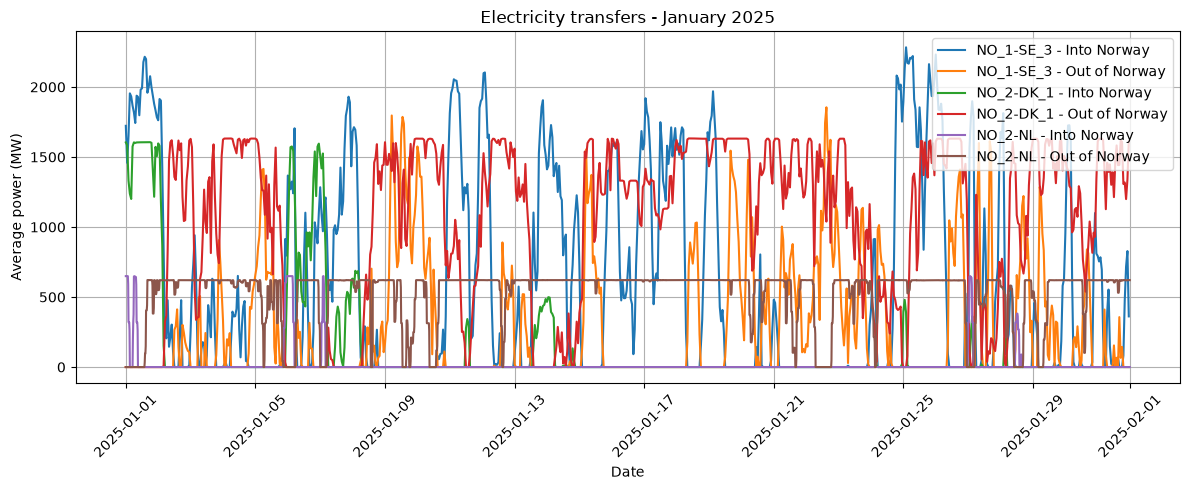

In [32]:
# Choose January 2025
january = daily[
    (daily["year"] == 2025) &
    (daily["month"] == 1)
]

# Make a graph
plt.figure(figsize=(12, 5))

# Draw one line for each connection and direction
for (connection, direction), group in january.groupby(
    ["connection", "direction"]
):
    group = group.sort_values("date")

    plt.plot(
        group["date"],
        group["mean_mw"],
        label=connection + " - " + direction
    )

# Add labels
plt.title("Electricity transfers - January 2025")
plt.xlabel("Date")
plt.ylabel("Average power (MW)")

plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
  

### AI usage declaration
In the beginning of the process both github and streamlit seemed daunting. Here AI was used to further understand what these pages could be used for as well as provide a good overall view of the project at hand. AI has also been used to find relevant commands and for further understanding. A prompt example being "What is the command in pandas for reading files such as reserviors.csv", here "pd.read_csv()" was provided from AI and further applied in the jupyter notebook. When first creating the streamlit app AI was used to find correct functions to best solve the task. In general AI has been used at all point during the assignment as there were many issues and error occuring all the time. 

### Project work log
For this assignment every simgle new thing to implement has taken at least 2-3 hours of work time. An old windows 10 computer seems to be the wrong choice for this assignment. However, some progress has been made. 

Docker desktop was not an easy installation, but after several work arounds and storage issues it is officialy up and running. Furthermore the implementation of Cassandra, Spark and MongoDB, has gone medium well. The Jupyter Notebook however is not fully completed as the tasks prooved to be a big time thief and difficult to manage. For this I apologise. The Streamlit app is therefore not updated as the nesseccary connections between Cassandra, spark and MongoDB have not worked. Thisis escpecially true for the Electricity Transfers page, which now just returns an error. 

The notebpook also does not run now due to only having java 8 (I know the current Java is at 17) but this computer does not want to cooperate. Hope some of the work shows a fraction of the hours spent angry at my computer. 

